# 数据集字段深度质量洞察 (DataField Quality Insights)

基于 `WebDataScope` 的本地高速缓存，穿透到具体的 Dataset 内部，查看每一个字段的十年来历年覆盖率和正态分布情况。
帮助您在动手测试之前，直接挑选出**高覆盖、无断层、分布均匀**的黄金字段！


In [1]:
import sys
import os

# 将当前目录加入系统路径，以便导入 wds_parser
current_dir = os.getcwd()
if current_dir not in sys.path:
    sys.path.append(current_dir)

import wds_parser
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

# 配置中文字体，防止图表显示方块
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

# 配置区域
WDS_DATA_DIR = r"d:\code\WorldQuant Brain\goal\WebDataScope-0.10.11\data"

# 1. 想要分析的目标维度 (填 None 或空字符串表示不限制，将合并分析所有匹配的)
TARGET_THEME = "None"       # 例如: "analyst", "fundamental", "model", "news", 或 None
TARGET_REGION = "CHN"       # 锁定在 GLB 大区
TARGET_UNIVERSE = "None"    # 放开股票池限制，捕获 MINVOL1M 等
TARGET_DELAY = "None"       # 放开 Delay 限制


## 1. 探索可用的数据集

In [2]:
# 2. 列出所有可用的 Dataset
datasets = wds_parser.list_available_datasets(WDS_DATA_DIR)
print(f"📊 发现 {len(datasets)} 个本地缓存的数据集。")
print("部分数据集预览:")
for d in datasets[:10]:
    print(f"  - {d}")
if len(datasets) > 10:
    print(f"  ... (及其他 {len(datasets)-10} 个)")


📊 发现 160 个本地缓存的数据集。
部分数据集预览:
  - analyst11_EUR_TOP1200_Delay1
  - analyst11_USA_TOP3000_Delay1
  - analyst14_CHN_TOP3000_Delay1
  - analyst14_EUR_TOP1200_Delay1
  - analyst14_JPN_TOP1600_Delay1
  - analyst14_USA_TOP3000_Delay1
  - analyst15_GLB_TOP3000_Delay1
  - analyst15_USA_TOP3000_Delay1
  - analyst16_EUR_TOP1200_Delay1
  - analyst16_USA_TOP3000_Delay1
  ... (及其他 150 个)


## 2. 字段质量全景表

In [3]:
# 3. 动态筛选并加载所有匹配数据集的字段特征
datasets = wds_parser.list_available_datasets(WDS_DATA_DIR)
matching_datasets = datasets

if TARGET_THEME and str(TARGET_THEME).strip().lower() != "none":
    matching_datasets = [d for d in matching_datasets if d.startswith(TARGET_THEME)]
if TARGET_REGION and str(TARGET_REGION).strip().lower() != "none":
    matching_datasets = [d for d in matching_datasets if f"_{TARGET_REGION}_" in d]
if TARGET_UNIVERSE and str(TARGET_UNIVERSE).strip().lower() != "none":
    matching_datasets = [d for d in matching_datasets if f"_{TARGET_UNIVERSE}_" in d]
if TARGET_DELAY and str(TARGET_DELAY).strip().lower() != "none":
    matching_datasets = [d for d in matching_datasets if d.endswith(TARGET_DELAY)]

print(f"🔍 当前筛选条件匹配到 {len(matching_datasets)} 个数据集。")
if len(matching_datasets) == 0:
    print("⚠️ 警告: 没有匹配到任何数据集，请检查您的配置！")
    df = pd.DataFrame()
else:
    print(f"🔄 正在批量解析并合并数据，请稍候...")
    all_dfs = []
    for ds in matching_datasets:
        target_file = os.path.join(WDS_DATA_DIR, f"{ds}.bin")
        temp_df = wds_parser.load_wds_bin(target_file)
        if len(temp_df) > 0:
            temp_df.insert(0, 'Dataset', ds) # 在第一列插入 Dataset 名称
            all_dfs.append(temp_df)
            
    if all_dfs:
        df = pd.concat(all_dfs, ignore_index=True)
        # 根据覆盖率重新排序全盘数据
        df = df.sort_values(by='AvgCoverage', ascending=False).reset_index(drop=True)
        print(f"✅ 解析成功！共在 {len(all_dfs)} 个数据集中发现 {len(df)} 个可用字段。")
        print("\n🏆 【全盘高覆盖率字段 Top 20】")
        display(df.head(20))
    else:
        print("❌ 无法解析这些数据集，或数据为空。")
        df = pd.DataFrame()


🔍 当前筛选条件匹配到 13 个数据集。
🔄 正在批量解析并合并数据，请稍候...


✅ 解析成功！共在 13 个数据集中发现 3011 个可用字段。

🏆 【全盘高覆盖率字段 Top 20】


,Dataset,Field,AvgCoverage,MinCoverage,MaxCoverage,AvgSkewness,AvgKurtosis,PositiveRatio,AbsRatio(0~1),IsInteger,Frequency,CoverageTrend
0,model175_CHN_TOP3000_Delay0,mdl175_pehist250,3.932,3.256,4.460,-1.0,-1.0,0.5,0.121,False,daily,"[3.534, 3.417, 3.585, 3.256, 3.752, 4.393, 4.4..."
1,model175_CHN_TOP3000_Delay0,mdl175_pehist120,3.878,3.035,4.449,-1.0,-1.0,0.5,0.122,False,daily,"[3.399, 3.035, 3.461, 3.474, 4.062, 4.318, 4.4..."
2,other41_CHN_TOP3000_Delay0,oth41_s_risk_treynorratio20,3.852,3.131,4.586,-1.0,-1.0,0.5,0.231,False,daily,"[3.187, 3.226, 3.131, 3.466, 3.63, 4.123, 4.52..."
3,model175_CHN_TOP3000_Delay0,mdl175_pehist60,3.821,3.162,4.534,-1.0,-1.0,0.5,0.121,False,daily,"[3.218, 3.474, 3.162, 3.566, 3.737, 4.166, 4.5..."
4,other41_CHN_TOP3000_Delay0,oth41_s_tech_br,3.780,2.822,4.786,-1.0,-1.0,0.5,0.122,False,daily,"[2.822, 2.999, 3.106, 3.134, 3.33, 4.059, 4.62..."
5,other41_CHN_TOP3000_Delay0,oth41_s_tech_cr20,3.750,2.815,4.232,-1.0,-1.0,0.5,0.118,False,daily,"[2.815, 3.293, 3.362, 3.443, 4.11, 4.232, 3.90..."
6,model175_CHN_TOP3000_Delay0,mdl175_treynorratio20,3.732,3.043,4.514,-1.0,-1.0,0.5,0.120,False,daily,"[3.15, 3.23, 3.043, 3.621, 3.602, 3.694, 4.514..."
7,other41_CHN_TOP3000_Delay0,oth41_s_tech_arbr,3.703,2.644,4.649,-1.0,-1.0,0.5,0.237,False,daily,"[2.644, 3.115, 3.146, 3.076, 3.361, 3.969, 4.2..."
8,other41_CHN_TOP3000_Delay0,oth41_s_risk_treynorratio60,3.672,2.537,4.412,-1.0,-1.0,0.5,0.245,False,daily,"[2.537, 2.792, 3.441, 2.922, 3.53, 4.091, 4.41..."
9,model175_CHN_TOP3000_Delay0,mdl175_treynorratio60,3.627,2.706,4.338,-1.0,-1.0,0.5,0.172,False,daily,"[2.706, 3.088, 3.434, 2.907, 3.349, 3.967, 4.1..."


## 3. 字段质量雷达图 (寻找最健康分布)

🌟 发现 619 个【Tier 1 黄金因子】 (高密度区Cov>0.9, 稀疏区Cov>0.3)


,Dataset,Field,AvgCoverage,MinCoverage,MaxCoverage,AvgSkewness,AvgKurtosis,PositiveRatio,AbsRatio(0~1),IsInteger,Frequency,CoverageTrend,QualityTier
17,other111_CHN_TOP3000_Delay1,oth111_replydivisionstat_posts_neu_regi_sum,1.752,1.260,2.302,-0.2,0.0,0.5,0.488,False,quarterly,"[1.601, 1.381, 1.992, 1.565, 1.961, 1.528, 2.2...",Tier 1 (黄金因子)
18,model175_CHN_TOP3000_Delay0,mdl175_ysp,1.652,1.474,1.852,0.0,-1.0,0.5,0.537,False,weekly,"[1.474, 1.527, 1.492, 1.554, 1.695, 1.654, 1.6...",Tier 1 (黄金因子)
19,other111_CHN_TOP3000_Delay1,oth111_replydivisionstat_posts_neu_alluser_sum,1.651,1.260,2.302,0.2,0.4,0.5,0.512,False,monthly,"[1.446, 1.288, 1.906, 1.437, 1.473, 1.47, 2.24...",Tier 1 (黄金因子)
21,other111_CHN_TOP3000_Delay1,oth111_devicedivisionstat_posts_neu_regi_sum,1.534,0.864,1.942,0.2,0.8,0.5,0.547,False,quarterly,"[0.864, 0.935, 1.285, 1.544, 1.786, 1.666, 1.9...",Tier 1 (黄金因子)
22,other111_CHN_TOP3000_Delay0,oth111_devicedivisionstat_posts_neu_regi_sum,1.530,0.864,1.957,0.2,0.8,0.5,0.548,False,quarterly,"[0.864, 0.931, 1.281, 1.523, 1.78, 1.664, 1.95...",Tier 1 (黄金因子)
23,other111_CHN_TOP3000_Delay1,oth111_devicedivisionstat_posts_neu_alluser_sum,1.476,1.014,1.942,0.5,1.0,0.5,0.548,False,monthly,"[1.059, 1.014, 1.254, 1.383, 1.376, 1.409, 1.9...",Tier 1 (黄金因子)
24,other111_CHN_TOP3000_Delay0,oth111_devicedivisionstat_posts_neu_alluser_sum,1.470,1.007,1.957,0.5,1.0,0.5,0.549,False,monthly,"[1.053, 1.007, 1.248, 1.355, 1.371, 1.408, 1.9...",Tier 1 (黄金因子)
26,other111_CHN_TOP3000_Delay1,oth111_devicedivisionstat_post_neu_sum,1.454,0.798,1.969,0.0,0.4,0.5,0.564,False,quarterly,"[0.947, 1.697, 1.111, 0.798, 0.94, 1.805, 1.92...",Tier 1 (黄金因子)
27,other111_CHN_TOP3000_Delay1,oth111_replydivisionstat_post_neu_sum,1.427,0.732,2.365,0.2,0.5,0.5,0.581,False,quarterly,"[0.732, 1.123, 0.975, 0.805, 1.583, 2.365, 1.6...",Tier 1 (黄金因子)
28,other41_CHN_TOP3000_Delay0,oth41_s_west_netprofit_ftm_1m,1.427,0.860,2.004,0.0,0.6,0.5,0.579,False,weekly,"[0.86, 0.96, 1.461, 2.004, 1.628, 1.38, 1.693,...",Tier 1 (黄金因子)


✨ 发现 1067 个【Tier 2 白银因子】 (高密度区Cov>0.8, 稀疏区Cov>0.15)


,Dataset,Field,AvgCoverage,MinCoverage,MaxCoverage,AvgSkewness,AvgKurtosis,PositiveRatio,AbsRatio(0~1),IsInteger,Frequency,CoverageTrend,QualityTier
2,other41_CHN_TOP3000_Delay0,oth41_s_risk_treynorratio20,3.852,3.131,4.586,-1.0,-1.0,0.5,0.231,False,daily,"[3.187, 3.226, 3.131, 3.466, 3.63, 4.123, 4.52...",Tier 2 (白银因子)
4,other41_CHN_TOP3000_Delay0,oth41_s_tech_br,3.780,2.822,4.786,-1.0,-1.0,0.5,0.122,False,daily,"[2.822, 2.999, 3.106, 3.134, 3.33, 4.059, 4.62...",Tier 2 (白银因子)
5,other41_CHN_TOP3000_Delay0,oth41_s_tech_cr20,3.750,2.815,4.232,-1.0,-1.0,0.5,0.118,False,daily,"[2.815, 3.293, 3.362, 3.443, 4.11, 4.232, 3.90...",Tier 2 (白银因子)
7,other41_CHN_TOP3000_Delay0,oth41_s_tech_arbr,3.703,2.644,4.649,-1.0,-1.0,0.5,0.237,False,daily,"[2.644, 3.115, 3.146, 3.076, 3.361, 3.969, 4.2...",Tier 2 (白银因子)
8,other41_CHN_TOP3000_Delay0,oth41_s_risk_treynorratio60,3.672,2.537,4.412,-1.0,-1.0,0.5,0.245,False,daily,"[2.537, 2.792, 3.441, 2.922, 3.53, 4.091, 4.41...",Tier 2 (白银因子)
10,other41_CHN_TOP3000_Delay0,oth41_s_risk_treynorratio120,3.434,2.161,4.202,-1.0,-1.0,0.5,0.266,False,daily,"[2.333, 2.161, 2.978, 2.989, 3.593, 4.104, 4.0...",Tier 2 (白银因子)
16,model175_CHN_TOP3000_Delay0,mdl175_41vme,1.767,1.258,2.262,-0.5,-0.2,0.5,0.381,False,daily,"[1.561, 1.278, 1.412, 1.258, 1.406, 1.956, 2.2...",Tier 2 (白银因子)
20,analyst14_CHN_TOP3000_Delay1,anl14_curperiodnum,1.547,0.719,3.635,0.4,0.4,0.5,0.056,True,semi-annual,"[0.719, 3.186, 3.635, 2.579, 1.101, 0.939, 0.8...",Tier 2 (白银因子)
32,other41_CHN_TOP3000_Delay0,oth41_s_tech_mktfaciind,1.413,1.122,1.636,0.6,1.0,0.5,0.018,False,daily,"[1.381, 1.448, 1.122, 1.204, 1.295, 1.6, 1.636...",Tier 2 (白银因子)
34,other41_CHN_TOP3000_Delay0,oth41_s_tech_emv6,1.402,0.927,2.116,-0.7,0.8,0.5,0.658,False,daily,"[0.927, 0.956, 1.155, 1.269, 1.266, 1.309, 1.6...",Tier 2 (白银因子)


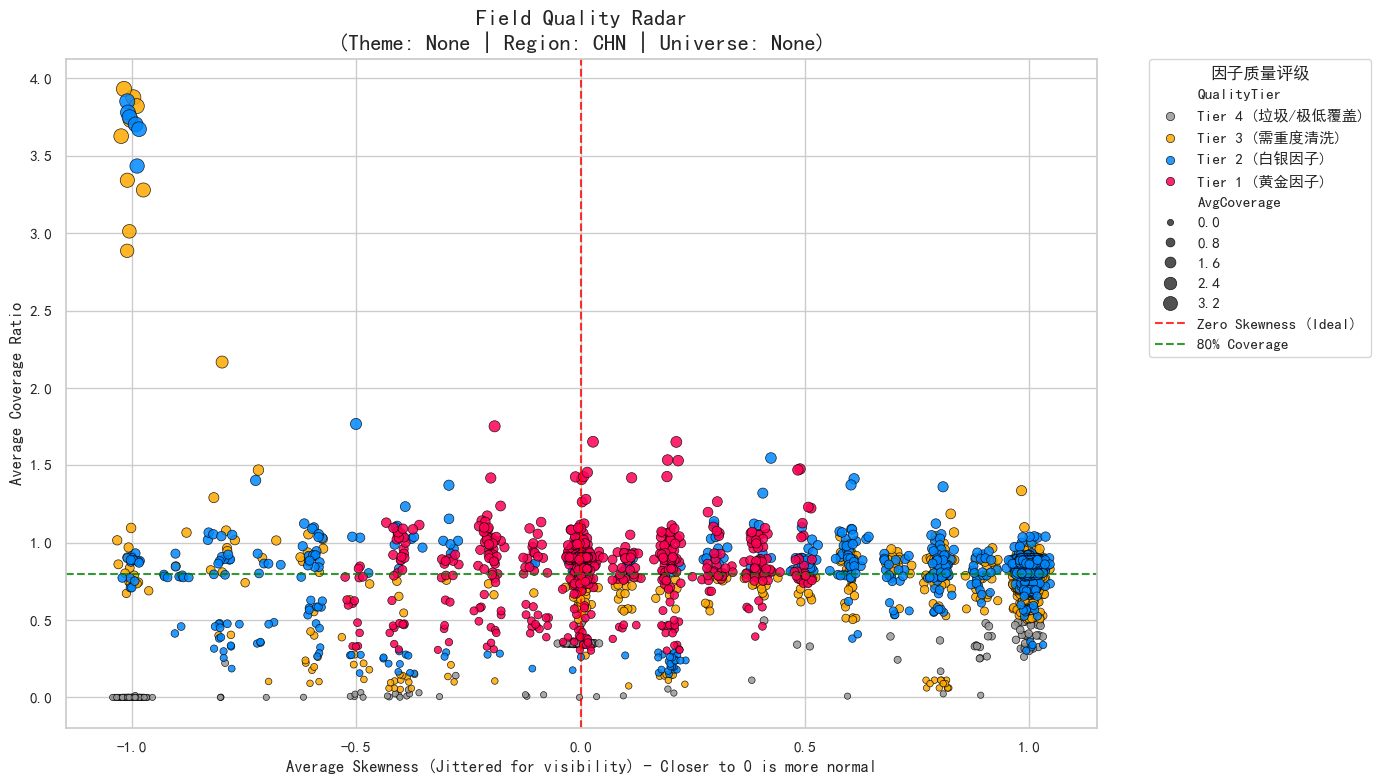

In [4]:
# 4. 可视化：字段质量散点分布图 (覆盖率 vs 偏度)
import numpy as np

def classify_field(row):
    cov = row['AvgCoverage']
    skew = abs(row['AvgSkewness'])
    pos_ratio = row['PositiveRatio']
    dataset = row.get('Dataset')
    if pd.isna(dataset):
        return 'Tier 4 (垃圾堆)'
    
    ds_str = str(dataset).lower()
    # 动态阈值判定：区分高密度矿区与稀疏矿区
    is_sparse = any(kw in ds_str for kw in ['news', 'sentiment', 'options', 'social', 'event', 'other'])
    
    # 设置对应的覆盖率门槛
    if is_sparse:
        t1_cov, t2_cov, t3_cov = 0.3, 0.15, 0.05
    else:
        t1_cov, t2_cov, t3_cov = 0.9, 0.8, 0.5
        
    # 判断是否为极端单边数据 (例如全是1或全是非0)
    is_extreme_ratio = (pos_ratio < 0.01) or (pos_ratio > 0.99)
    
    # Tier 1 在稀疏数据中可能由于 0 值过多导致偏度较高，因此放宽偏度要求
    t1_skew = 0.5 if is_sparse else 0.2
    t2_skew = 1.0 if is_sparse else 0.5
    
    if cov >= t1_cov and skew <= t1_skew and not is_extreme_ratio:
        return 'Tier 1 (黄金因子)'
    elif cov >= t2_cov and skew <= t2_skew and not is_extreme_ratio:
        return 'Tier 2 (白银因子)'
    elif cov >= t3_cov:
        return 'Tier 3 (需重度清洗)'
    else:
        return 'Tier 4 (垃圾/极低覆盖)'

if len(df) > 0:
    plot_df = df.copy()
    # 评级分类
    plot_df['QualityTier'] = plot_df.apply(classify_field, axis=1)
    
    # 打印评级推荐表
    tier1_df = plot_df[plot_df['QualityTier'] == 'Tier 1 (黄金因子)']
    tier2_df = plot_df[plot_df['QualityTier'] == 'Tier 2 (白银因子)']
    
    print(f"🌟 发现 {len(tier1_df)} 个【Tier 1 黄金因子】 (高密度区Cov>0.9, 稀疏区Cov>0.3)")
    if len(tier1_df) > 0:
        display(tier1_df.head(10))
        
    print(f"✨ 发现 {len(tier2_df)} 个【Tier 2 白银因子】 (高密度区Cov>0.8, 稀疏区Cov>0.15)")
    if len(tier2_df) > 0:
        display(tier2_df.head(10))

    plt.figure(figsize=(14, 8))
    sns.set_theme(style="whitegrid")
    # 必须在 set_theme 之后重新设置字体，否则会被 seaborn 覆盖
    plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS', 'sans-serif']
    plt.rcParams['axes.unicode_minus'] = False
    
    # 加一点点随机扰动以看清密度
    plot_df['JitteredSkewness'] = plot_df['AvgSkewness'] + np.random.normal(0, 0.015, size=len(plot_df))
    
    # 为不同的 Tier 定义高对比度、极其醒目的颜色
    tier_palette = {
        'Tier 1 (黄金因子)': '#FF0055',   # 亮骚粉/玫红 (极其醒目)
        'Tier 2 (白银因子)': '#0088FF',   # 亮蓝色
        'Tier 3 (需重度清洗)': '#FFAA00', # 橙色
        'Tier 4 (垃圾/极低覆盖)': '#999999'  # 灰色，融入背景
    }
    
    # 根据评级画散点图
    scatter = sns.scatterplot(
        data=plot_df.sort_values('QualityTier', ascending=False), # 让金银色在上层
        x="JitteredSkewness", 
        y="AvgCoverage", 
        hue="QualityTier", 
        palette=tier_palette, 
        size="AvgCoverage",       
        sizes=(20, 120),          
        alpha=0.85,               # 提高不透明度，让颜色更实、更饱满
        edgecolor='black',
        linewidth=0.5
    )
    
    plt.axvline(0, color='red', linestyle='dashed', alpha=0.8, label='Zero Skewness (Ideal)')
    plt.axhline(0.8, color='green', linestyle='dashed', alpha=0.8, label='80% Coverage')
    
    plt.title(f"Field Quality Radar\n(Theme: {TARGET_THEME} | Region: {TARGET_REGION} | Universe: {TARGET_UNIVERSE})", fontsize=16)
    plt.xlabel("Average Skewness (Jittered for visibility) - Closer to 0 is more normal", fontsize=12)
    plt.ylabel("Average Coverage Ratio", fontsize=12)
    
    plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0., title="因子质量评级")
    plt.tight_layout()
    plt.show()


## 4. 导出字段明细至 Excel

In [5]:
# 5. 导出详情至 Excel 文件
import datetime
import os

if len(df) > 0:
    timestamp = datetime.datetime.now().strftime("%Y%md_%H%M%S")
    theme_str = TARGET_THEME if TARGET_THEME and TARGET_THEME.lower() != 'none' else 'ALL'
    region_str = TARGET_REGION if TARGET_REGION and TARGET_REGION.lower() != 'none' else 'ALL'
    
    export_dir = "exports"
    if not os.path.exists(export_dir):
        os.makedirs(export_dir)
        
    excel_filename = os.path.join(export_dir, f"Field_Quality_Report_{theme_str}_{region_str}_{timestamp}.xlsx")
    
    # 按照质量评级排序后导出，并剔除画图专用的干扰列
    export_df = plot_df.sort_values(['QualityTier', 'AvgCoverage'], ascending=[True, False])
    if 'JitteredSkewness' in export_df.columns:
        export_df = export_df.drop(columns=['JitteredSkewness'])
    if 'CoverageTrend' in export_df.columns:
        export_df = export_df.drop(columns=['CoverageTrend'])
        
    export_df.to_excel(excel_filename, index=False)
    
    print(f"✅ 已成功将所有字段统计详情导出至 Excel 文件: {excel_filename}")
    print("您可以在当前目录中找到该文件并使用 Excel 或 WPS 打开查看。")
else:
    print("没有数据可以导出。")


✅ 已成功将所有字段统计详情导出至 Excel 文件: exports\Field_Quality_Report_ALL_CHN_202608d_214410.xlsx
您可以在当前目录中找到该文件并使用 Excel 或 WPS 打开查看。


## 5. 数据集矿区大比武 (Dataset Family Combat)

🏆 【各大矿区含金量排行榜】


QualityTier,Tier 1 (黄金因子),Tier 2 (白银因子),Tier 3 (需重度清洗),Tier 4 (垃圾/极低覆盖)
Dataset,,,,
other41_CHN_TOP3000_Delay0,192,327,3,0
other395_CHN_TOP3000_Delay1,190,108,13,0
other111_CHN_TOP3000_Delay1,71,217,0,0
model175_CHN_TOP3000_Delay0,56,125,241,0
other79_CHN_TOP3000_Delay1,53,85,40,24
other111_CHN_TOP3000_Delay0,33,158,0,103
pv27_CHN_TOP3000_Delay0,12,21,159,11
other395_CHN_TOP3000_Delay1_wrong,11,1,0,0
pv1_CHN_TOP3000_Delay1,1,0,10,1


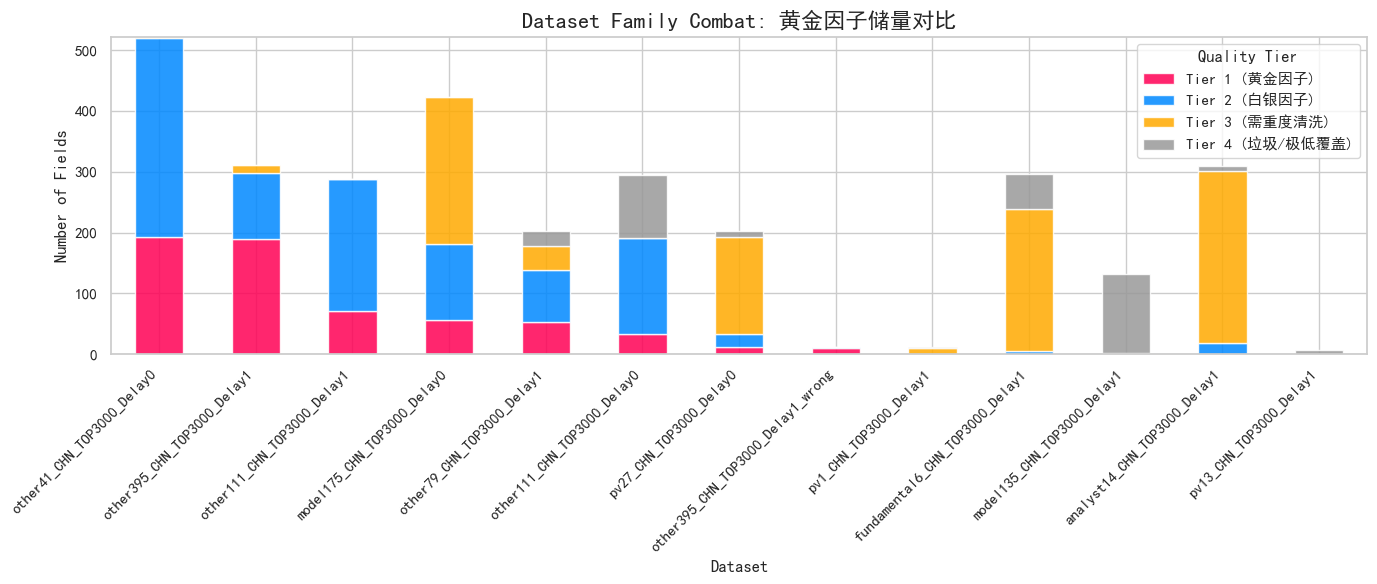

✅ 矿区大比武数据已归档至: exports\Dataset_Combat_Report_ALL_CHN_202608d_214410.xlsx


In [6]:
# 6. 数据集矿区大比武 (Dataset Family Combat)
# 统计哪个数据集产出的 Tier 1 黄金因子最多
if len(df) > 0:
    combat_df = plot_df.groupby(['Dataset', 'QualityTier']).size().unstack(fill_value=0)
    
    # 确保所有列存在
    for tier in ['Tier 1 (黄金因子)', 'Tier 2 (白银因子)', 'Tier 3 (需重度清洗)', 'Tier 4 (垃圾/极低覆盖)']:
        if tier not in combat_df.columns:
            combat_df[tier] = 0
            
    # 按黄金因子数量排序
    combat_df = combat_df.sort_values('Tier 1 (黄金因子)', ascending=False)
    
    print("🏆 【各大矿区含金量排行榜】")
    display(combat_df)
    
    # 绘制堆叠柱状图
    combat_df[['Tier 1 (黄金因子)', 'Tier 2 (白银因子)', 'Tier 3 (需重度清洗)', 'Tier 4 (垃圾/极低覆盖)']].plot(
        kind='bar', stacked=True, figsize=(14, 6), 
        color=['#FF0055', '#0088FF', '#FFAA00', '#999999'], alpha=0.85
    )
    plt.title("Dataset Family Combat: 黄金因子储量对比", fontsize=16)
    plt.xlabel("Dataset", fontsize=12)
    plt.ylabel("Number of Fields", fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.legend(title="Quality Tier")
    plt.tight_layout()
    plt.show()
    
    # 导出这个精简版的比武图表到 Excel
    combat_excel = os.path.join(export_dir, f"Dataset_Combat_Report_{theme_str}_{region_str}_{timestamp}.xlsx")
    combat_df.to_excel(combat_excel)
    print(f"✅ 矿区大比武数据已归档至: {combat_excel}")


## 6. 优质因子岁月考验 (Time-Series Stability)

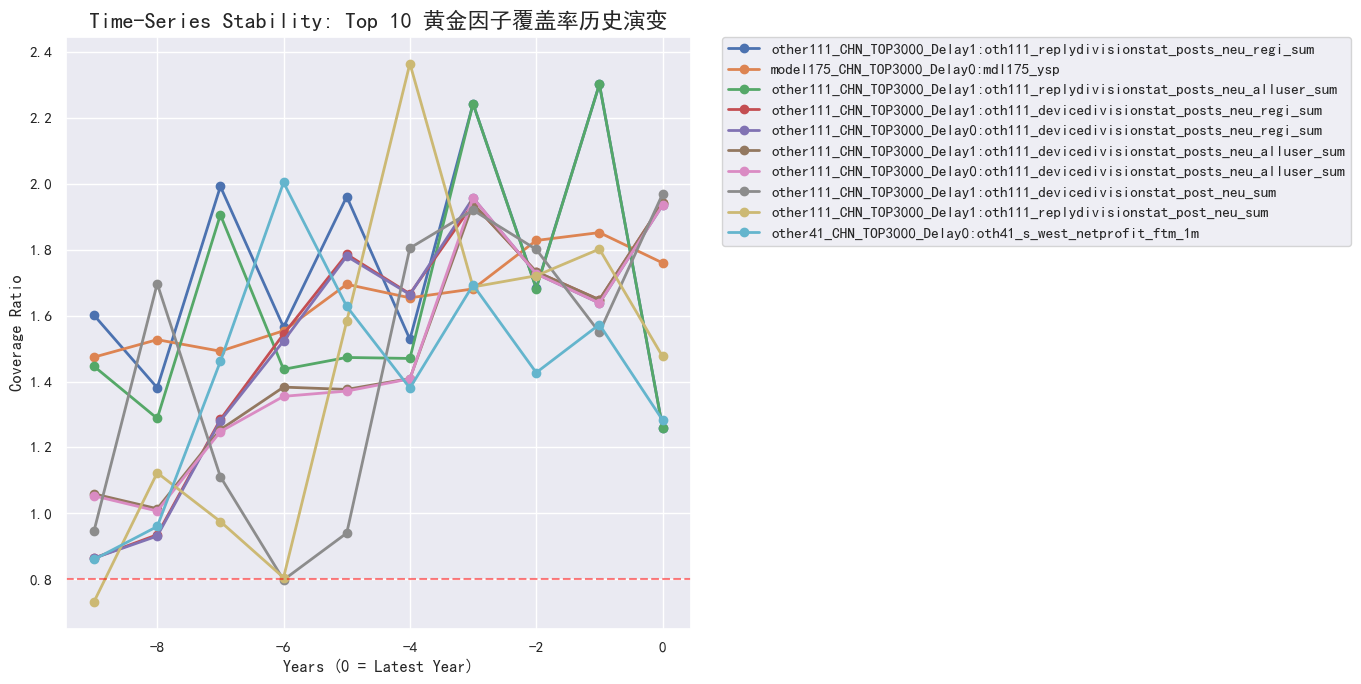

In [7]:
# 7. 优质因子岁月考验 (Time-Series Stability)
# 抓取 Top 10 的 Tier 1 因子，画出它们历年的覆盖率折线图，看看有没有逐年衰退
if len(df) > 0 and 'Tier 1 (黄金因子)' in plot_df['QualityTier'].values:
    top10_tier1 = plot_df[plot_df['QualityTier'] == 'Tier 1 (黄金因子)'].sort_values('AvgCoverage', ascending=False).head(10)
    
    plt.figure(figsize=(14, 7))
    sns.set_theme(style="darkgrid")
    plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Arial Unicode MS', 'sans-serif']
    plt.rcParams['axes.unicode_minus'] = False
    
    valid_lines = 0
    for idx, row in top10_tier1.iterrows():
        trend = row['CoverageTrend']
        if isinstance(trend, list) and len(trend) > 0:
            # X 轴简单用 -N 到 0 表示相对年份
            x_axis = range(-len(trend) + 1, 1)
            plt.plot(x_axis, trend, marker='o', linewidth=2, label=f"{row['Dataset']}:{row['Field']}")
            valid_lines += 1
            
    if valid_lines > 0:
        plt.title("Time-Series Stability: Top 10 黄金因子覆盖率历史演变", fontsize=16)
        plt.xlabel("Years (0 = Latest Year)", fontsize=12)
        plt.ylabel("Coverage Ratio", fontsize=12)
        plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
        plt.axhline(0.8, color='red', linestyle='dashed', alpha=0.5, label='80% Danger Line')
        plt.tight_layout()
        plt.show()
    else:
        print("这批数据集没有包含时序演变数组数据 (CoverageTrend为空)。")
else:
    print("当前筛选条件下没有足够的 Tier 1 因子来绘制岁月考验图。")


## 7. 终极精选名单 (The Ultimate Whitelist)

In [8]:
# 8. 终极精选名单 (The Ultimate Whitelist) - 广度优先版 (Stratified Selection)
# 为了保证因子的多样性，我们放弃单纯的“全局 Top N” 机制，否则像 analyst 这种大矿区会挤占其他矿区的生存空间。
# 现在的机制是：按数据集(Dataset)分组，在每个数据集中，优先挑选出满足“严苛岁月考验”的 Tier 1 (甚至优质 Tier 2) 因子。
# 并且限制每个数据集最多只输出 20 个字段，保证最终的名单兼顾【极高胜率】与【极大的广度】。

if len(df) > 0:
    ultimate_whitelist = []
    
    # 按照 Dataset 分组
    grouped = plot_df.groupby('Dataset')
    
    for dataset, group_df in grouped:
        dataset_whitelist = []
        is_sparse = any(kw in str(dataset).lower() for kw in ['news', 'sentiment', 'options', 'social', 'event', 'other'])
        
        # 对于稀疏矿区，开启极限捞底通道：允许 Tier 3 (5% 覆盖率) 因子入围
        if is_sparse:
            allowed_tiers = ['Tier 1 (黄金因子)', 'Tier 2 (白银因子)', 'Tier 3 (需重度清洗)']
        else:
            allowed_tiers = ['Tier 1 (黄金因子)', 'Tier 2 (白银因子)']
            
        qualified_group = group_df[group_df['QualityTier'].isin(allowed_tiers)].copy()
        
        if len(qualified_group) > 0:
            # 首先按 QualityTier 升序 (Tier 1 优先)，然后再按 AvgCoverage 降序排列
            qualified_group = qualified_group.sort_values(['QualityTier', 'AvgCoverage'], ascending=[True, False])
            
            for idx, row in qualified_group.iterrows():
                trend = row['CoverageTrend']
                
                # 严苛的“岁月考验”过滤
                # 高密度矿区底线：0.8， 稀疏矿区底线：0.1
                # 对于开启 Tier 3 打捞的，进一步放宽至 0.05
                stability_floor = 0.05 if is_sparse else 0.8
                
                passed_test = False
                if isinstance(trend, list) and len(trend) >= 3:
                    recent_3_years = trend[-3:]
                    if all(val >= stability_floor for val in recent_3_years):
                        passed_test = True
                elif isinstance(trend, list) and len(trend) > 0:
                    # 如果数据历史不足 3 年，但仅有的几年都达标也放行
                    if all(val >= stability_floor for val in trend):
                        passed_test = True
                        
                if passed_test:
                    dataset_whitelist.append(f"{row['Dataset']}/{row['Field']}")
            
            # 将该矿区挑选出的优质因子加入总名单
            ultimate_whitelist.extend(dataset_whitelist)
            
    print(f"🎯 经过多重严格过滤与【广度优先分层抽样】（无强行截断），最终为您锁定 【{len(ultimate_whitelist)}】 个极品因子！")
        
    if len(ultimate_whitelist) > 0:
        print("\n👇 请直接复制以下列表到您的 Alpha 挖掘脚本中：\n")
        print("TARGET_FIELDS = [")
        for f in ultimate_whitelist:
            print(f"    '{f}',")
        print("]")
        
        # 导出至 txt
        whitelist_filename = os.path.join(export_dir, f"Ultimate_Whitelist_Stratified_{theme_str}_{region_str}_{timestamp}.txt")
        with open(whitelist_filename, 'w', encoding='utf-8') as wf:
            wf.write("TARGET_FIELDS = [\n")
            for f in ultimate_whitelist:
                wf.write(f"    '{f}',\n")
            wf.write("]\n")
        print(f"\n✅ 白名单已自动归档至专用文件夹: {whitelist_filename}")
    else:
        print("⚠️ 很遗憾，即使开启了极限下沉打捞通道，也没有因子能扛过稳定性测试，白名单为空。")
else:
    print("没有数据可以处理。")


🎯 经过多重严格过滤与【广度优先分层抽样】（无强行截断），最终为您锁定 【1740】 个极品因子！

👇 请直接复制以下列表到您的 Alpha 挖掘脚本中：

TARGET_FIELDS = [
    'analyst14_CHN_TOP3000_Delay1/anl14_mean_eps_fy1',
    'analyst14_CHN_TOP3000_Delay1/anl14_median_eps_fy1',
    'analyst14_CHN_TOP3000_Delay1/anl14_outperform',
    'analyst14_CHN_TOP3000_Delay1/anl14_buy',
    'analyst14_CHN_TOP3000_Delay1/anl14_hold',
    'analyst14_CHN_TOP3000_Delay1/anl14_mean_epsrep_fy1',
    'analyst14_CHN_TOP3000_Delay1/anl14_median_epsrep_fy1',
    'analyst14_CHN_TOP3000_Delay1/anl14_low_epsrep_fy1',
    'analyst14_CHN_TOP3000_Delay1/anl14_underperform',
    'analyst14_CHN_TOP3000_Delay1/anl14_sell',
    'analyst14_CHN_TOP3000_Delay1/anl14_median_roe_fy2',
    'analyst14_CHN_TOP3000_Delay1/anl14_low_bvps_fy1',
    'analyst14_CHN_TOP3000_Delay1/anl14_low_roe_fy2',
    'analyst14_CHN_TOP3000_Delay1/anl14_high_roe_fy2',
    'analyst14_CHN_TOP3000_Delay1/anl14_mean_bvps_fy1',
    'analyst14_CHN_TOP3000_Delay1/anl14_median_bvps_fy1',
    'analyst14_CHN_TOP3000_Delay